# TP2 - Etapa 2: entrenamiento, evaluación y comparación de modelos

Notebook de entrenamiento y estudio de resultados: evaluación de la búsqueda por similitud
(Etapa 1, NDCG@10), fine-tuning de ResNet (Modelo A), CNN propia (Modelo B) y comparación entre
modelos (ver `ENUNCIADO.md`, secciones 4.3 y 5). **Ambos modelos son obligatorios.**

El entrenamiento se realiza en Colab para aprovechar la GPU:
**Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)**.

Requisitos previos (en tu fork):
- Funciones de la Etapa 1 implementadas en `src/lib/services/similarity_service.py`.
- `train_classifier`, `evaluate_classifier` y `extract_custom_embedding` implementadas en
  `src/lib/services/classifier_service.py` (esta notebook solo las orquesta).
- Splits y conjunto independiente generados en `1-pre-processing.ipynb`.

Al finalizar:
- Descargar los checkpoints generados y colocarlos en `models/` del entorno local
  (la aplicación los usa en las pestañas de las Etapas 1, 2 y 3).
- Publicarlos en un link público de solo lectura para los docentes.
- Entregar esta notebook ejecutada, con sus salidas.

**Notebook en Google Colab:** no aplica. La notebook se ejecutó en Colab (GPU T4) y esta copia del repositorio contiene todas sus salidas.

## Equipo
- Alumno 1 : CHIAPPE, Maximiliano - C-7542/6
- Alumno 2 : LENARDUZZI, Juan - L-3398/7

## 1. Clonar el repositorio

Solo si trabajan en Colab. Si tu fork es privado, generá un token de acceso (GitHub → Settings →
Developer settings → Personal access tokens) y usalo en la URL, o subí un zip del proyecto a Colab/Drive.

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
print("Corriendo en Colab:", IN_COLAB)

if IN_COLAB:
    REPO_URL = "https://github.com/MaxiChiappe/tuia-dog-recognition-app.git"
    if not Path("/content/proyecto").exists():
        !git clone -b feature/tp2-razas-perros $REPO_URL /content/proyecto
    %cd /content/proyecto

Corriendo en Colab: True
Cloning into '/content/proyecto'...
remote: Enumerating objects: 211, done.
remote: Counting objects: 100% (82/82), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 211 (delta 55), reused 60 (delta 48), pack-reused 129 (from 1)
Receiving objects: 100% (211/211), 12.35 MiB | 21.44 MiB/s, done.
Resolving deltas: 100% (117/117), done.
/content/proyecto


## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.

In [6]:
if IN_COLAB:
        !pip install -q pydantic-settings python-dotenv kagglehub albumentations==2.0.8 ultralytics onnxruntime
else:
    print("Local: las dependencias ya están instaladas en el .venv (requirements.txt)")

## 3. Configuración del entorno

En Colab no hay PostgreSQL, por lo que se desactiva pgvector y se usa la base vectorial JSON.
La configuración se define por variables de entorno **antes** de importar `lib`.

In [3]:
import os
import sys
from pathlib import Path

os.environ["USE_PGVECTOR"] = "false"
# Ajustá acá cualquier otra variable (IMAGE_SIZE, EMBEDDING_DIM, paths, etc.)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings

import torch
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data/dataset
GPU disponible: True


## 4. Dataset y splits

Se cargan los splits filtrados de `1-pre-processing.ipynb` (`data/splits.csv`) y el conjunto independiente (`data/dataset/independent/`). Para la evaluación se usan solo sus imágenes **limpias** (un perro, raza conocida); las escenas y los gatos se usan en la Etapa 3.

En Colab, el dataset se descarga de Kaggle y el resto (splits, conjunto independiente y embeddings baseline ya calculados) se copia desde Google Drive, porque no está en el repositorio.

In [4]:
import shutil
import pandas as pd
from lib.training import load_split

if IN_COLAB:
    !python scripts/download_dataset.py
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive/TP2_perros")
    for nombre, destino in {"splits.csv": settings.splits_file, "emb_baseline.npz": settings.output_path / "emb_baseline.npz"}.items():
        if not destino.exists():
            destino.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy(DRIVE_DIR / nombre, destino)
    if not (settings.dataset_path / "independent").exists():
        shutil.copytree("/content/drive/MyDrive/independent", settings.dataset_path / "independent")

splits = {s: load_split(settings.splits_file, settings.dataset_path, s) for s in ["train", "valid", "test"]}
for s, items in splits.items():
    print(f"{s}: {len(items)} imágenes")

ind_dir = settings.dataset_path / "independent"
fuentes = pd.read_csv(ind_dir / "fuentes.csv")
independiente = [(ind_dir / r.archivo, r.raza) for r in fuentes[fuentes.tipo == "limpia"].itertuples()]
print(f"independiente (limpias): {len(independiente)} imágenes, {fuentes[fuentes.tipo == 'limpia'].raza.nunique()} razas")

Descargando gpiosenka/70-dog-breedsimage-data-set ...
Using Colab cache for faster access to the '70-dog-breedsimage-data-set' dataset.
Dataset disponible en /content/proyecto/data/dataset
Mounted at /content/drive
train: 7810 imágenes
valid: 693 imágenes
test: 696 imágenes
independiente (limpias): 119 imágenes, 21 razas


## 5. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

**Galería:** imágenes de `train` (7810). **Consultas:** `test` (696) y el conjunto independiente (119 limpias), nunca indexadas. `valid` se usa solo para calibrar el umbral.

Se usa la misma `extract_embedding` de la app (ResNet18 ImageNet, 512 dimensiones, normalizado L2). Como sugiere el enunciado, la búsqueda se hace con un producto matricial en numpy, sin la base de datos.

### 5.1 Embeddings baseline
Se guardan en `output/emb_baseline.npz` para no recalcularlos en cada ejecución.

In [7]:
import cv2
import numpy as np
from lib.bootstrap import build_similarity, build_store
from lib.evaluation.metrics import ndcg_at_k

similarity = build_similarity(settings, build_store(settings))

def embeddings_de(items, extraer):
    return np.array([extraer(cv2.imread(str(p))) for p, _ in items], dtype=np.float32)

conjuntos = {"train": splits["train"], "valid": splits["valid"], "test": splits["test"], "independiente": independiente}

cache = settings.output_path / "emb_baseline.npz"
if cache.exists():
    emb_base = dict(np.load(cache))
else:
    emb_base = {nombre: embeddings_de(items, similarity.extract_embedding) for nombre, items in conjuntos.items()}
    settings.output_path.mkdir(parents=True, exist_ok=True)
    np.savez(cache, **emb_base)

for nombre, m in emb_base.items():
    print(f"{nombre}: {m.shape}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
train: (7810, 512)
valid: (693, 512)
test: (696, 512)
independiente: (119, 512)


### 5.2 NDCG@10, precision@10 y accuracy: cosine vs l2

Para cada consulta se recuperan los 10 vecinos más parecidos y se calcula:
- **NDCG@10** con relevancia binaria, usando `ndcg_at_k` con `n_relevant` = imágenes de la raza en la galería.
- **precision@10**: proporción de vecinos de la raza correcta.
- **accuracy**: si acierta la raza predicha por `predict_breed_from_neighbors` (la misma función de la app, voto ponderado).

Umbral actual del `.env`: 0.55; se calibra en 5.4.

In [8]:
from lib.schemas import Neighbor

razas_galeria = np.array([raza for _, raza in splits["train"]])
rutas_galeria = [str(p) for p, _ in splits["train"]]
imgs_por_raza = pd.Series(razas_galeria).value_counts()

def scores_de(consultas, galeria, metrica):
    if metrica == "cosine":
        return consultas @ galeria.T
    # l2: distancia euclídea -> score = 1 / (1 + distancia), igual que similarity() de la app
    dist2 = (consultas**2).sum(1)[:, None] + (galeria**2).sum(1)[None, :] - 2 * consultas @ galeria.T
    return 1 / (1 + np.sqrt(np.maximum(dist2, 0)))

def evaluar(emb, consulta, metrica, k=10):
    scores = scores_de(emb[consulta], emb["train"], metrica)
    filas = []
    for i, (ruta, raza) in enumerate(conjuntos[consulta]):
        top = np.argsort(-scores[i])[:k]
        rel = razas_galeria[top] == raza
        vecinos = [Neighbor(path=rutas_galeria[j], breed=razas_galeria[j], score=float(scores[i, j])) for j in top]
        pred, _ = similarity.predict_breed_from_neighbors(vecinos)
        filas.append({"ruta": str(ruta), "raza": raza, "pred": pred, "top1_score": scores[i, top[0]],
                      "ndcg": ndcg_at_k(rel, k, imgs_por_raza[raza]), "precision": rel.mean(), "acierto": pred == raza})
    return pd.DataFrame(filas)

resultados = {(c, m): evaluar(emb_base, c, m) for c in ["test", "independiente"] for m in ["cosine", "l2"]}
tabla_etapa1 = pd.DataFrame({
    (c, m): {"NDCG@10": r.ndcg.mean(), "precision@10": r.precision.mean(),
             "accuracy": r.acierto.mean(), "unknown": (r.pred == "unknown").mean()}
    for (c, m), r in resultados.items()
}).T.round(3)
tabla_etapa1

NDCG@10  precision@10  accuracy  unknown
test          cosine    0.874         0.861     0.937      0.0
              l2        0.874         0.861     0.937      0.0
independiente cosine    0.773         0.766     0.840      0.0
              l2        0.773         0.766     0.840      0.0

**Resultados.**
- **cosine y l2 dan exactamente lo mismo.** Con embeddings normalizados L2, `distancia² = 2 − 2·cos`, así que el orden de los vecinos es idéntico. Solo cambia la escala del score, por eso el umbral se calibra para cosine, la métrica que usa la app.
- **test: NDCG@10 = 0.874, accuracy = 0.937.** Sin entrenar nada, los embeddings de ImageNet ya separan bien las razas; ImageNet incluye más de 100 razas de perros.
- **independiente: NDCG@10 = 0.773, accuracy = 0.840.** Baja unos 10 puntos por el cambio de dominio: las fotos de Oxford y Stanford tienen otros fondos y encuadres que las de Kaggle, que vienen recortadas al perro.
- Con el umbral de 0.55 no hay ningún `unknown`.

### 5.3 Efecto de TOP_K

`TOP_K` define cuántos vecinos se recuperan y, por lo tanto, cuántos votan la raza. Se compara precision@k y accuracy para distintos valores de K (métrica cosine).

In [9]:
filas = []
for k in [1, 3, 5, 10, 20, 50]:
    for c in ["test", "independiente"]:
        r = evaluar(emb_base, c, "cosine", k=k)
        filas.append({"TOP_K": k, "consulta": c, "precision@k": r.precision.mean(), "accuracy": r.acierto.mean()})

efecto_k = pd.DataFrame(filas).pivot(index="TOP_K", columns="consulta").round(3)
efecto_k

precision@k             accuracy       
consulta independiente   test independiente   test
TOP_K                                             
1                0.798  0.930         0.798  0.930
3                0.776  0.899         0.815  0.937
5                0.778  0.885         0.840  0.943
10               0.766  0.861         0.840  0.937
20               0.734  0.827         0.866  0.931
50               0.677  0.759         0.857  0.917

**Resultados.**
- **precision@k baja al subir K** (test: 0.930 con K=1 y 0.759 con K=50): cuanto más lejos se busca, más vecinos de otras razas aparecen.
- **La accuracy casi no cambia** (test: 0.930–0.943, máximo con K=5): el voto ponderado tolera algunos vecinos equivocados.
- En el independiente mejora hasta K=20 (0.866), pero con 119 imágenes la diferencia son 3 o 4 consultas: no es concluyente.
- **Se mantiene `TOP_K=10`**: es el valor que pide el enunciado y queda a menos de 1 punto del mejor.

### 5.4 Calibración del umbral (SIMILARITY_THRESHOLD) con valid

Si el score del vecino más cercano queda por debajo del umbral, la app responde `unknown`. Criterio: percentil 1 de los scores top-1 de `valid`, redondeado hacia abajo, para que a lo sumo el 1% de los perros conocidos quede como `unknown`. Después se verifica en test, en el independiente y con 10 imágenes de gatos que no se usaron para calibrar.

Umbral calibrado (percentil 1 de valid, redondeado hacia abajo): 0.82
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 136MB/s]


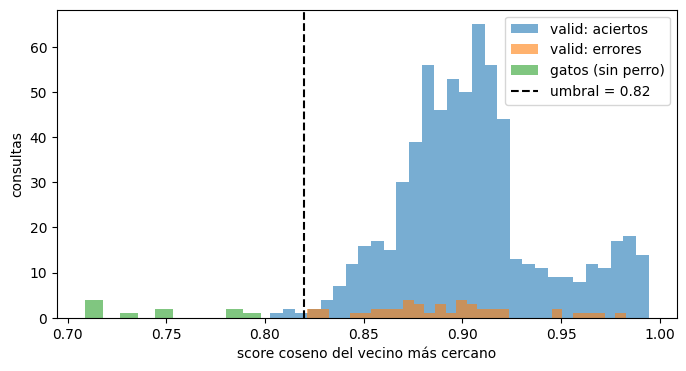

,conjunto,aceptadas,accuracy aceptadas,rechazadas,"de ellas, errores"
0,valid,0.994,0.938,4,0.0
1,test,0.991,0.939,6,2.0
2,independiente,0.882,0.867,14,5.0
3,gatos,0.000,NaN,10,NaN


In [10]:
import math
import matplotlib.pyplot as plt

valid = evaluar(emb_base, "valid", "cosine")
umbral = math.floor(float(np.percentile(valid.top1_score, 1)) * 100) / 100
print(f"Umbral calibrado (percentil 1 de valid, redondeado hacia abajo): {umbral}")

gatos = [ind_dir / a for a in fuentes[fuentes.tipo == "sin_perro"].archivo]
emb_gatos = embeddings_de([(p, None) for p in gatos], similarity.extract_embedding)
top1_gatos = (emb_gatos @ emb_base["train"].T).max(axis=1)

plt.figure(figsize=(8, 4))
plt.hist(valid[valid.acierto].top1_score, bins=30, alpha=0.6, label="valid: aciertos")
plt.hist(valid[~valid.acierto].top1_score, bins=30, alpha=0.6, label="valid: errores")
plt.hist(top1_gatos, bins=10, alpha=0.6, label="gatos (sin perro)")
plt.axvline(umbral, color="k", linestyle="--", label=f"umbral = {umbral}")
plt.xlabel("score coseno del vecino más cercano"); plt.ylabel("consultas"); plt.legend()
plt.show()

filas = []
for nombre, r in [("valid", valid), ("test", resultados[("test", "cosine")]), ("independiente", resultados[("independiente", "cosine")])]:
    aceptadas = r[r.top1_score >= umbral]
    filas.append({"conjunto": nombre, "aceptadas": len(aceptadas) / len(r), "accuracy aceptadas": aceptadas.acierto.mean(),
                  "rechazadas": (r.top1_score < umbral).sum(), "de ellas, errores": (~r[r.top1_score < umbral].acierto).sum()})
filas.append({"conjunto": "gatos", "aceptadas": (top1_gatos >= umbral).mean(), "rechazadas": (top1_gatos < umbral).sum()})
pd.DataFrame(filas).round(3)

**Resultados.**
- **Umbral calibrado: 0.82.** El anterior (0.55) no rechazaba nada: el score top-1 más bajo de valid es 0.80.
- **No separa aciertos de errores**: en el histograma, los errores tienen scores tan altos como los aciertos (0.85–0.97). Cuando falla, la búsqueda encuentra un perro muy parecido de otra raza.
- **Sí separa perro de no perro**: los 10 gatos (scores 0.71–0.80) quedan como `unknown`.
- **Costo**: se rechaza el 0.9% de test y el 11.8% del independiente, porque las fotos de otro dominio se parecen menos a la galería. Preferimos `unknown` a dar una raza para algo que no es un perro.

### 5.5 Resultados por raza y razas más confundidas

NDCG@10 y accuracy por raza en test y en el independiente, y los pares (raza real → predicha) más frecuentes entre los errores.

In [11]:
r_test = resultados[("test", "cosine")]
r_ind = resultados[("independiente", "cosine")]

por_raza = pd.DataFrame({
    "NDCG test": r_test.groupby("raza").ndcg.mean(), "accuracy test": r_test.groupby("raza").acierto.mean(),
    "NDCG indep": r_ind.groupby("raza").ndcg.mean(), "accuracy indep": r_ind.groupby("raza").acierto.mean(),
})
print("10 razas con peor NDCG@10 en test:")
display(por_raza.sort_values("NDCG test").head(10).round(3))

print("8 razas con peor NDCG@10 en el independiente:")
display(por_raza.dropna().sort_values("NDCG indep").head(8).round(3))

errores = pd.concat([r_test, r_ind])
errores = errores[~errores.acierto]
print("Pares más confundidos (raza real -> predicha), test + independiente:")
display(errores.groupby(["raza", "pred"]).size().sort_values(ascending=False).head(12).rename("errores"))

misma = r_test.raza.isin(r_ind.raza.unique())
print(f"Test restringido a las 21 razas del independiente: NDCG@10 = {r_test[misma].ndcg.mean():.3f}, "
      f"accuracy = {r_test[misma].acierto.mean():.3f}")

10 razas con peor NDCG@10 en test:


,NDCG test,accuracy test,NDCG indep,accuracy indep
raza,,,,
Bulldog,0.329,0.300,NaN,NaN
Malinois,0.553,0.800,NaN,NaN
Labradoodle,0.613,0.700,NaN,NaN
Cockapoo,0.637,0.889,NaN,NaN
Boston Terrier,0.654,0.800,NaN,NaN
Rhodesian,0.659,0.700,NaN,NaN
Bull Mastiff,0.672,0.700,NaN,NaN
American Spaniel,0.689,0.800,NaN,NaN
Bull Terrier,0.694,0.700,NaN,NaN


8 razas con peor NDCG@10 en el independiente:


,NDCG test,accuracy test,NDCG indep,accuracy indep
raza,,,,
Shiba Inu,0.827,0.9,0.520,0.667
Japanese Spaniel,0.894,0.9,0.575,0.833
Pit Bull,0.898,0.9,0.635,0.667
Beagle,0.908,1.0,0.637,0.667
Rottweiler,0.922,1.0,0.643,0.600
German Sheperd,0.774,0.8,0.653,0.600
Boxer,0.950,1.0,0.698,1.000
Labrador,0.911,1.0,0.719,0.833


Pares más confundidos (raza real -> predicha), test + independiente:


,,errores
raza,pred,
Bulldog,Boston Terrier,4
German Sheperd,Malinois,4
Bull Mastiff,Boxer,3
Labradoodle,Cockapoo,3
Bull Terrier,Basenji,2
Bulldog,French Bulldog,2
Boston Terrier,Bulldog,2
American Spaniel,Irish Spaniel,2
Shiba Inu,Dingo,2


Test restringido a las 21 razas del independiente: NDCG@10 = 0.914, accuracy = 0.971


**Resultados.**
- **Los errores son entre razas visualmente parecidas**: Bulldog ↔ Boston Terrier / French Bulldog (hocico chato), German Sheperd → Malinois, Bull Mastiff → Boxer, Rhodesian → Vizsla, Labradoodle → Cockapoo (las dos son cruzas con caniche).
- **Bulldog es la peor raza en test** (NDCG 0.33, accuracy 0.30): se confunde en ambos sentidos con dos razas muy parecidas.
- **El cambio de dominio pesa unos 14 puntos.** Con las mismas 21 razas, test da NDCG 0.914 y el independiente 0.773. Shiba Inu, Rottweiler y Beagle andan bien en test y caen en las fotos de Oxford/Stanford.
- El embedding de ImageNet capta la apariencia general pero no los detalles finos entre razas cercanas; es lo que busca mejorar la Etapa 2.

### 5.6 Ejemplos visuales: consultas y sus Top-10

Consulta a la izquierda y sus 10 vecinos con raza y score (verde = misma raza, rojo = otra). Se muestran 4 errores representativos y 1 acierto como contraste.

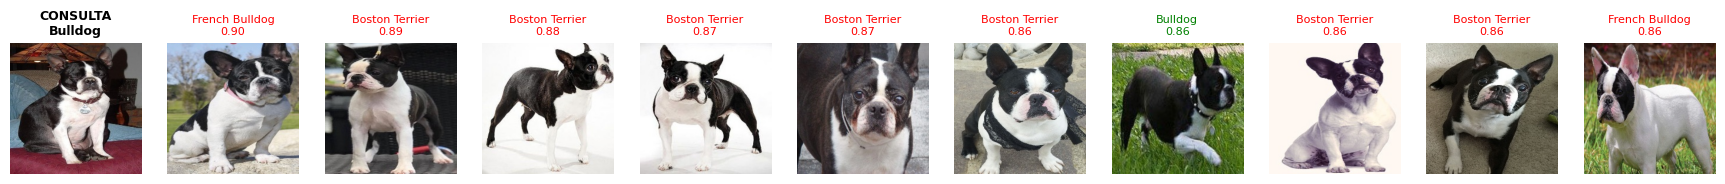

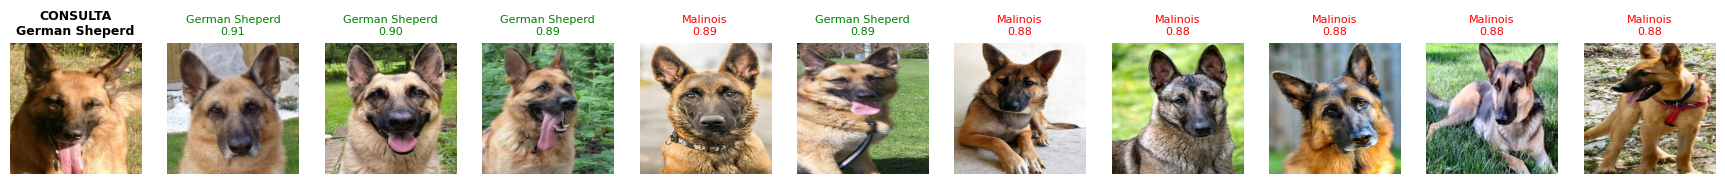

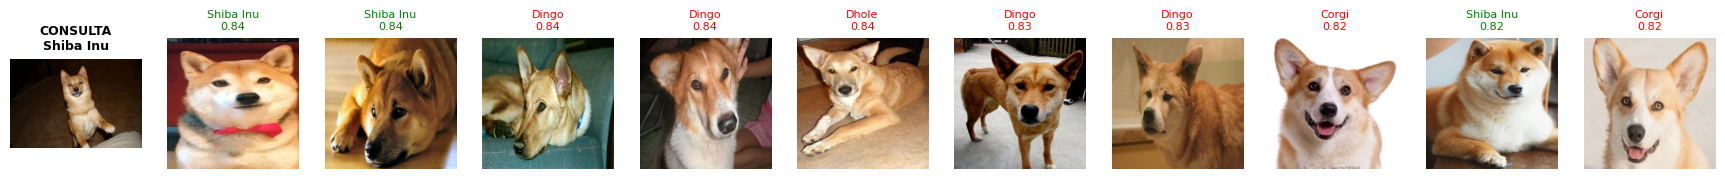

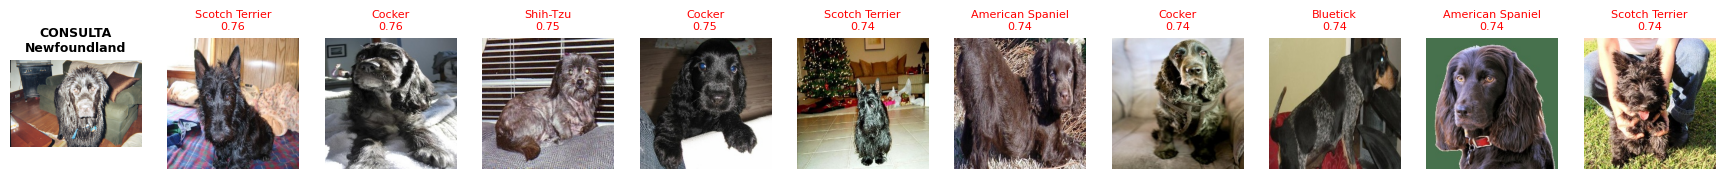

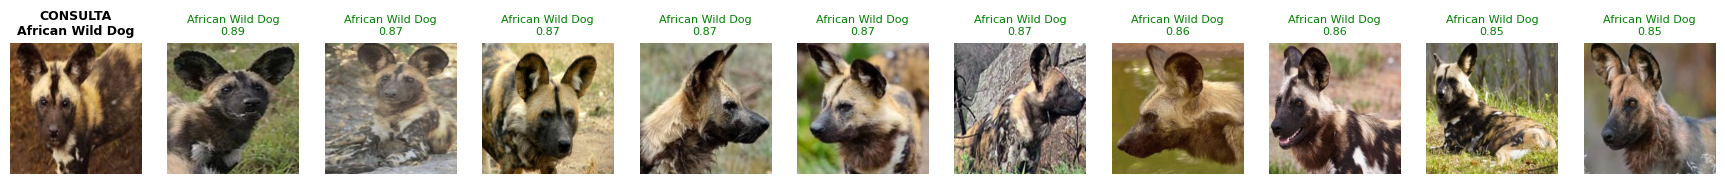

In [12]:
def mostrar_top10(emb, consulta, i):
    ruta, raza = conjuntos[consulta][i]
    scores = emb[consulta][i] @ emb["train"].T
    top = np.argsort(-scores)[:10]
    fig, axes = plt.subplots(1, 11, figsize=(22, 2.8))
    axes[0].imshow(cv2.cvtColor(cv2.imread(str(ruta)), cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"CONSULTA\n{raza}", fontsize=9, fontweight="bold")
    for ax, j in zip(axes[1:], top):
        ax.imshow(cv2.cvtColor(cv2.imread(rutas_galeria[j]), cv2.COLOR_BGR2RGB))
        ax.set_title(f"{razas_galeria[j]}\n{scores[j]:.2f}", fontsize=8,
                     color="green" if razas_galeria[j] == raza else "red")
    for ax in axes:
        ax.axis("off")
    plt.show()

ejemplos = [
    ("test", r_test[(r_test.raza == "Bulldog") & (r_test.pred == "Boston Terrier")].index[0]),
    ("test", r_test[(r_test.raza == "German Sheperd") & (r_test.pred == "Malinois")].index[0]),
    ("independiente", r_ind[(r_ind.raza == "Shiba Inu") & (r_ind.pred == "Dingo")].index[0]),
    ("independiente", r_ind[~r_ind.acierto].sort_values("top1_score").index[0]),
    ("test", r_test[r_test.acierto].sort_values("ndcg", ascending=False).index[0]),
]
for consulta, i in ejemplos:
    mostrar_top10(emb_base, consulta, i)

**Análisis de los ejemplos.**
- **Bulldog → Boston Terrier**: la consulta tiene orejas de murciélago y pelaje blanco y negro, más propios de un Boston Terrier o un Bulldog Francés. Hipótesis: hay ruido de etiquetas en la clase Bulldog, lo que explica en parte su NDCG bajo.
- **German Sheperd → Malinois**: los 4 primeros vecinos son correctos, pero varios "Malinois" de la galería tienen el pelo largo del pastor alemán. Son razas emparentadas, con posibles etiquetas cruzadas.
- **Shiba Inu → Dingo** (independiente): el perro ocupa poco de una foto oscura, mientras que Kaggle viene recortado al perro. Los vecinos comparten color rojizo y orejas paradas.
- **Newfoundland → Cocker** (independiente): todos los vecinos son perros negros de otras razas, porque el embedding prioriza color y textura sobre forma y tamaño. Score 0.76 < 0.82, así que la app respondería `unknown`, que es lo buscado.
- **Yorkie** (acierto): raza muy distintiva, 10 de 10 vecinos correctos.

**Conclusión:** el baseline anda muy bien en el dominio del dataset y falla en razas cercanas, fotos de otro dominio y etiquetas dudosas.

## 6. Modelo A (obligatorio): fine-tuning de ResNet18

**Estrategia:** ResNet18 preentrenada en ImageNet, con la capa final reemplazada por una cabeza propia (Dropout + Linear a 70 razas). Se prueba:
- `head`: backbone congelado, solo se entrena la cabeza (rápido, poco riesgo de sobreajuste).
- `layer4`: además se descongela el último bloque convolucional, para que ajuste los rasgos finos de cada raza.

**Hiperparámetros:** AdamW (lr 1e-3, weight decay 1e-4), batch 32, scheduler coseno, CrossEntropy con label smoothing 0.1, dropout 0.3 y early stopping por accuracy de valid (paciencia 5); se guarda el mejor checkpoint. Augmentation solo en train: flip horizontal, rotación ±15°, blur, brillo/contraste y ruido (ver `1-pre-processing.ipynb`). Las BatchNorm de las capas congeladas quedan en modo eval.

El checkpoint se copia a Drive al terminar, por si Colab se desconecta.

In [17]:
import logging
from lib.bootstrap import build_classifier

logging.getLogger().setLevel(logging.INFO)  # muestra el log de cada época (en Colab viene apagado)

EPOCAS_A = 20  # máximo; el early stopping corta antes si valid deja de mejorar

classifier = build_classifier(settings)
classifier.train_config.epochs = EPOCAS_A
classifier.train_config.patience = 5
classifier.train_config.resnet_finetune = "head"
classifier.set_active_model("resnet18_finetuned")
classifier.train_classifier()

if IN_COLAB:
    shutil.copy(classifier.active_checkpoint, DRIVE_DIR)
    shutil.copy(settings.output_path / "history_resnet18_finetuned.json", DRIVE_DIR)

INFO:lib.services.classifier_service:Training resnet18_finetuned: 7810 train / 693 valid images, 70 breeds
INFO:lib.services.classifier_service:Trainable params: 35910 / 11212422 | device: cuda
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 1/20 - train loss 2.2054 acc 0.5981 | val loss 1.2451 acc 0.9019 | 28s
INFO:lib.services.classifier_service:New best val acc 0.9019 -> saved models/resnet18_finetuned.pth
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 2/20 - train loss 1.4404 acc 0.8197 | val loss 1.1634 acc 0.9322 | 29s
INFO:lib.services.classifier_service:New best val acc 0.9322 -> saved models/resnet18_finetuned.pth
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 3/20 - train loss 1.3663 acc 0.8464 | val loss 1.1491 acc 0.9322 | 29s
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 4/20 - train loss 1.3319 acc 0.8599 | val loss 1.1283 acc 0.9293 | 29s
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 5/

In [18]:
metrics_a = classifier.evaluate_classifier()
metrics_a

INFO:lib.services.classifier_service:Predictions saved to output/predictions_resnet18_finetuned_test.csv
INFO:lib.services.classifier_service:[resnet18_finetuned] metrics on test: {'accuracy': 0.9525862068965517, 'precision': 0.9583807858807859, 'recall': 0.9525396825396826, 'specificity': 0.9993128469639349, 'f1': 0.9516756466445906}


{'accuracy': 0.9525862068965517,
 'precision': 0.9583807858807859,
 'recall': 0.9525396825396826,
 'specificity': 0.9993128469639349,
 'f1': 0.9516756466445906}

**Resultados (estrategia `head`).**
- **Mejor época: 16 de 20**, con 94.7% de accuracy en valid; ese es el checkpoint guardado. El early stopping no llegó a cortar.
- **Converge muy rápido:** 90% en valid tras la primera época y meseta en 93–94.7% desde la segunda. Con el backbone congelado, solo se aprende la cabeza (36 mil parámetros) sobre rasgos de ImageNet que ya distinguen razas.
- **Accuracy de train menor que la de valid** (90% contra 94%): en train se mide con augmentation, dropout y label smoothing activos, que dificultan la tarea a propósito. No hay sobreajuste: la loss de valid baja hasta la última época.
- **Test: accuracy 95.3%, precision 95.8%, recall 95.3%, F1 0.952** (promedio macro). Supera al baseline de la Etapa 1 (93.7% con vecinos más cercanos).
- La meseta en ~94% sugiere que el límite está en los rasgos congelados; por eso se prueba también `layer4` (tabla de experimentos).

### Curvas de entrenamiento y matriz de confusión (Modelo A)

Loss y accuracy por época (train y valid, desde el historial que guarda `train_classifier`) y matriz de confusión normalizada en test (cada fila suma 1), con los pares de razas más confundidos.

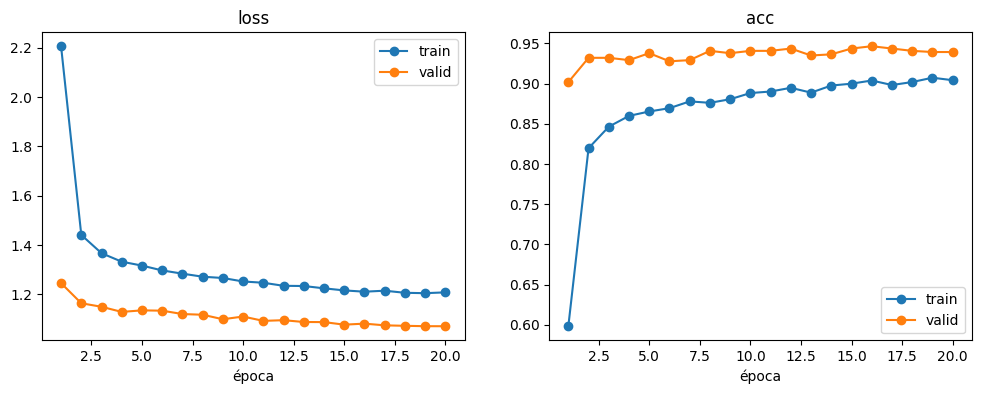

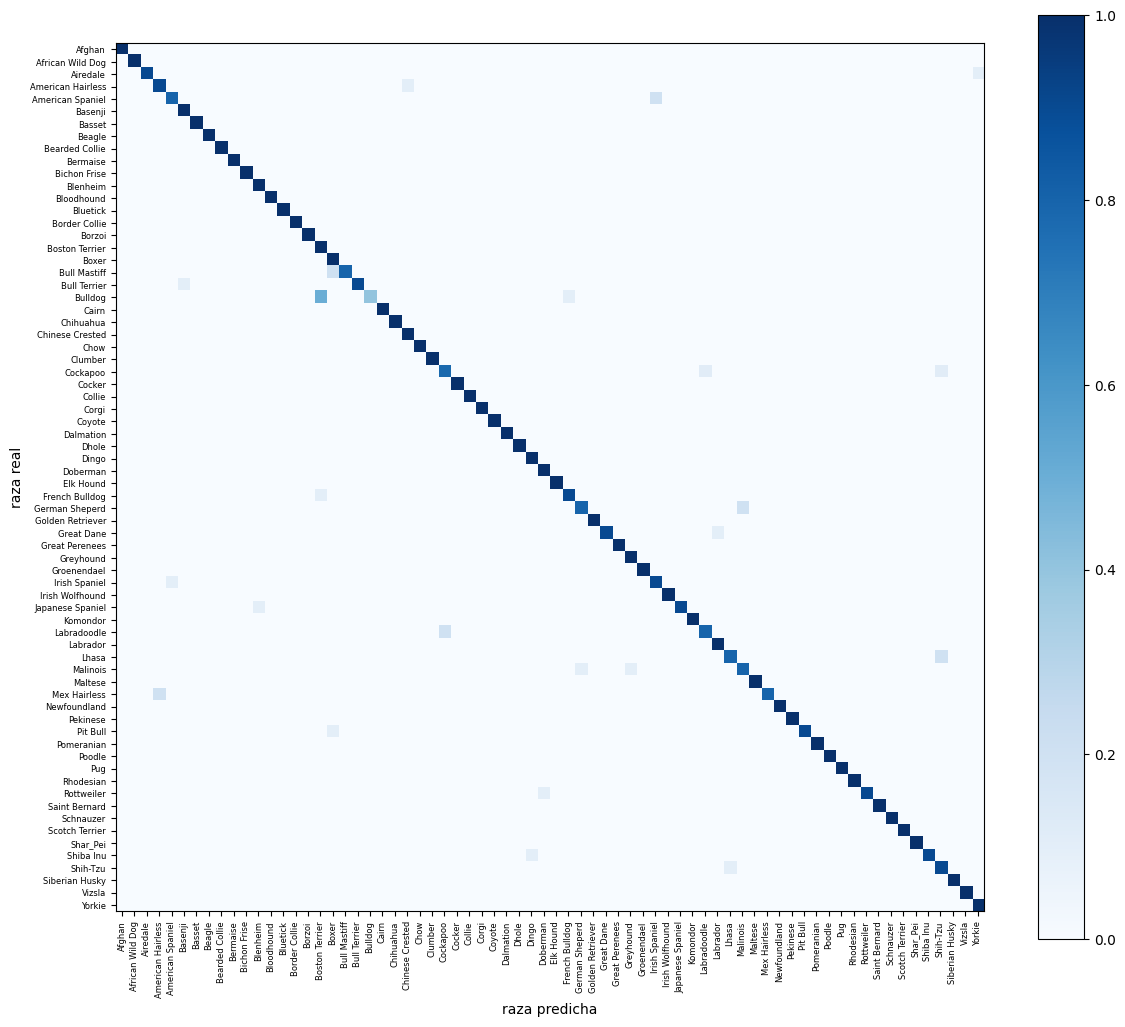

,,errores
true,pred,
Bulldog,Boston Terrier,5
Bull Mastiff,Boxer,2
American Spaniel,Irish Spaniel,2
Lhasa,Shih-Tzu,2
Mex Hairless,American Hairless,2
Labradoodle,Cockapoo,2
German Sheperd,Malinois,2
Bulldog,French Bulldog,1
Bull Terrier,Basenji,1


In [21]:
import json
from sklearn.metrics import confusion_matrix

def graficar_curvas(nombre):
    hist = pd.DataFrame(json.loads((settings.output_path / f"history_{nombre}.json").read_text())["history"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for metrica, ax in zip(["loss", "acc"], axes):
        ax.plot(hist.epoch, hist[f"train_{metrica}"], marker="o", label="train")
        ax.plot(hist.epoch, hist[f"val_{metrica}"], marker="o", label="valid")
        ax.set_xlabel("época"); ax.set_title(metrica); ax.legend()
    plt.show()

def matriz_confusion(nombre, n_pares=10):
    pred = pd.read_csv(settings.output_path / f"predictions_{nombre}_test.csv")
    razas = sorted(pred["true"].unique())
    cm = confusion_matrix(pred["true"], pred["pred"], labels=razas, normalize="true")
    plt.figure(figsize=(14, 12))
    plt.imshow(cm, cmap="Blues")
    plt.xticks(range(len(razas)), razas, rotation=90, fontsize=6)
    plt.yticks(range(len(razas)), razas, fontsize=6)
    plt.xlabel("raza predicha"); plt.ylabel("raza real"); plt.colorbar()
    plt.show()
    errores = pred[pred["true"] != pred["pred"]]
    return errores.groupby(["true", "pred"]).size().sort_values(ascending=False).head(n_pares).rename("errores")

graficar_curvas("resnet18_finetuned")
matriz_confusion("resnet18_finetuned")

**Análisis (Modelo A).**
- **Curvas:** la loss de train cae fuerte en las primeras 2 épocas y después baja de a poco; la de valid baja de forma pareja hasta el final, sin repuntes. La accuracy de valid se estabiliza en ~93–95% desde la época 2. Train queda siempre por debajo de valid porque se mide con augmentation, dropout y label smoothing: **no hay sobreajuste**.
- **Matriz de confusión:** diagonal casi completa; la mayoría de las razas acierta 9 o 10 de sus 10 imágenes de test. Los errores son puntos aislados fuera de la diagonal.
- **Peor raza: Bulldog**, que va 5 de 10 veces a Boston Terrier y 1 a French Bulldog. Coincide con lo visto en la Etapa 1, donde la clase parecía tener etiquetas dudosas.
- **Pares más confundidos:** casi los mismos que con el baseline (Bull Mastiff → Boxer, German Sheperd → Malinois, Labradoodle → Cockapoo, American Spaniel → Irish Spaniel), más Lhasa → Shih-Tzu y Mex Hairless → American Hairless. Son razas visualmente muy cercanas: el fine-tuning de la cabeza mejora la accuracy general, pero no resuelve los pares difíciles, porque los rasgos del backbone siguen siendo los de ImageNet.

## 7. Modelo B (obligatorio): CNN propia

**Arquitectura** (`src/lib/models/cnn_custom.py`): 5 bloques convolucionales (32 → 64 → 128 → 256 → 256 canales), Global Average Pooling, una capa Linear + BatchNorm + ReLU que da el **embedding de 512 dimensiones** (el mismo tamaño que ResNet18, así sirve para la búsqueda) y la cabeza Dropout + Linear a 70 razas. Unos 1.15 M parámetros, entrenados desde cero.

**Hiperparámetros:** los mismos que el Modelo A (AdamW lr 1e-3, batch 32, coseno, label smoothing 0.1, dropout 0.3, mismo augmentation), pero con más épocas y más paciencia, porque una red desde cero tarda más en converger.

In [19]:
EPOCAS_B = 40  # máximo; el early stopping corta antes si valid deja de mejorar

classifier.train_config.epochs = EPOCAS_B
classifier.train_config.patience = 8
classifier.set_active_model("cnn_custom")
classifier.train_classifier()

if IN_COLAB:
    shutil.copy(classifier.active_checkpoint, DRIVE_DIR)
    shutil.copy(settings.output_path / "history_cnn_custom.json", DRIVE_DIR)

INFO:lib.services.classifier_service:Training cnn_custom: 7810 train / 693 valid images, 70 breeds
INFO:lib.services.classifier_service:Trainable params: 1147750 / 1147750 | device: cuda
INFO:lib.services.classifier_service:[cnn_custom] epoch 1/40 - train loss 4.0631 acc 0.0564 | val loss 3.9511 acc 0.0707 | 32s
INFO:lib.services.classifier_service:New best val acc 0.0707 -> saved models/cnn_custom.pth
INFO:lib.services.classifier_service:[cnn_custom] epoch 2/40 - train loss 3.7718 acc 0.1055 | val loss 3.6418 acc 0.1356 | 31s
INFO:lib.services.classifier_service:New best val acc 0.1356 -> saved models/cnn_custom.pth
INFO:lib.services.classifier_service:[cnn_custom] epoch 3/40 - train loss 3.5187 acc 0.1577 | val loss 3.3369 acc 0.1861 | 31s
INFO:lib.services.classifier_service:New best val acc 0.1861 -> saved models/cnn_custom.pth
INFO:lib.services.classifier_service:[cnn_custom] epoch 4/40 - train loss 3.3355 acc 0.1899 | val loss 3.4318 acc 0.1775 | 31s
INFO:lib.services.classifier_

In [20]:
metrics_b = classifier.evaluate_classifier()
metrics_b

INFO:lib.services.classifier_service:Predictions saved to output/predictions_cnn_custom_test.csv
INFO:lib.services.classifier_service:[cnn_custom] metrics on test: {'accuracy': 0.7873563218390804, 'precision': 0.8010771371485657, 'recall': 0.7871825396825398, 'specificity': 0.9969179811662654, 'f1': 0.7844212444735297}


{'accuracy': 0.7873563218390804,
 'precision': 0.8010771371485657,
 'recall': 0.7871825396825398,
 'specificity': 0.9969179811662654,
 'f1': 0.7844212444735297}

**Resultados.**
- **Mejor época: 35 de 40**, con 81.5% de accuracy en valid; ese es el checkpoint guardado.
- **Aprende lento y constante:** 7% de valid en la época 1, 45% en la 10, 66% en la 20 y 80% en la 30. Desde cero, la red tiene que aprender desde los bordes y texturas hasta los rasgos de cada raza.
- **Sobreajuste moderado al final:** train llega a 93% y valid se queda en ~81%, a pesar del augmentation y el dropout. Con ~110 imágenes por raza, la red empieza a memorizar el train.
- **Meseta en las últimas épocas:** el scheduler coseno lleva el learning rate casi a 0 en la época 40, así que el modelo ya no cambia.
- **Test: accuracy 78.7%, precision 80.1%, recall 78.7%, F1 0.784** (macro). Unos 17 puntos menos que el Modelo A: es el costo de no partir de ImageNet, con 10 veces menos parámetros (1.15 M contra 11.2 M).

### Curvas de entrenamiento y matriz de confusión (Modelo B)

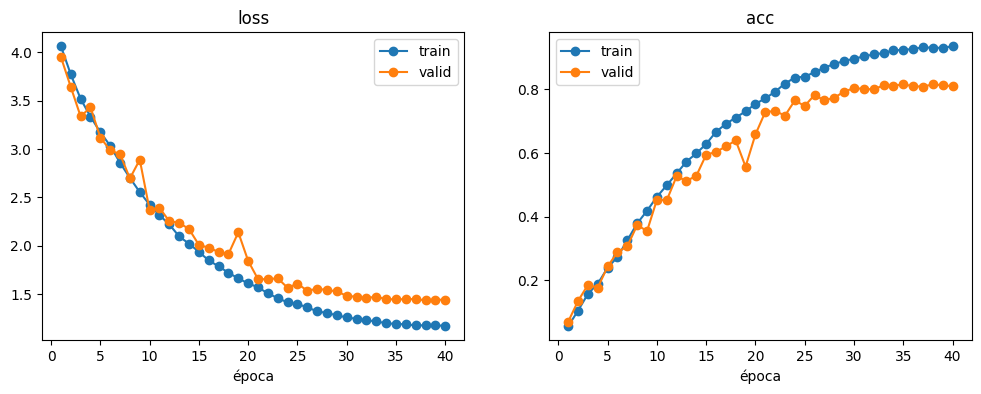

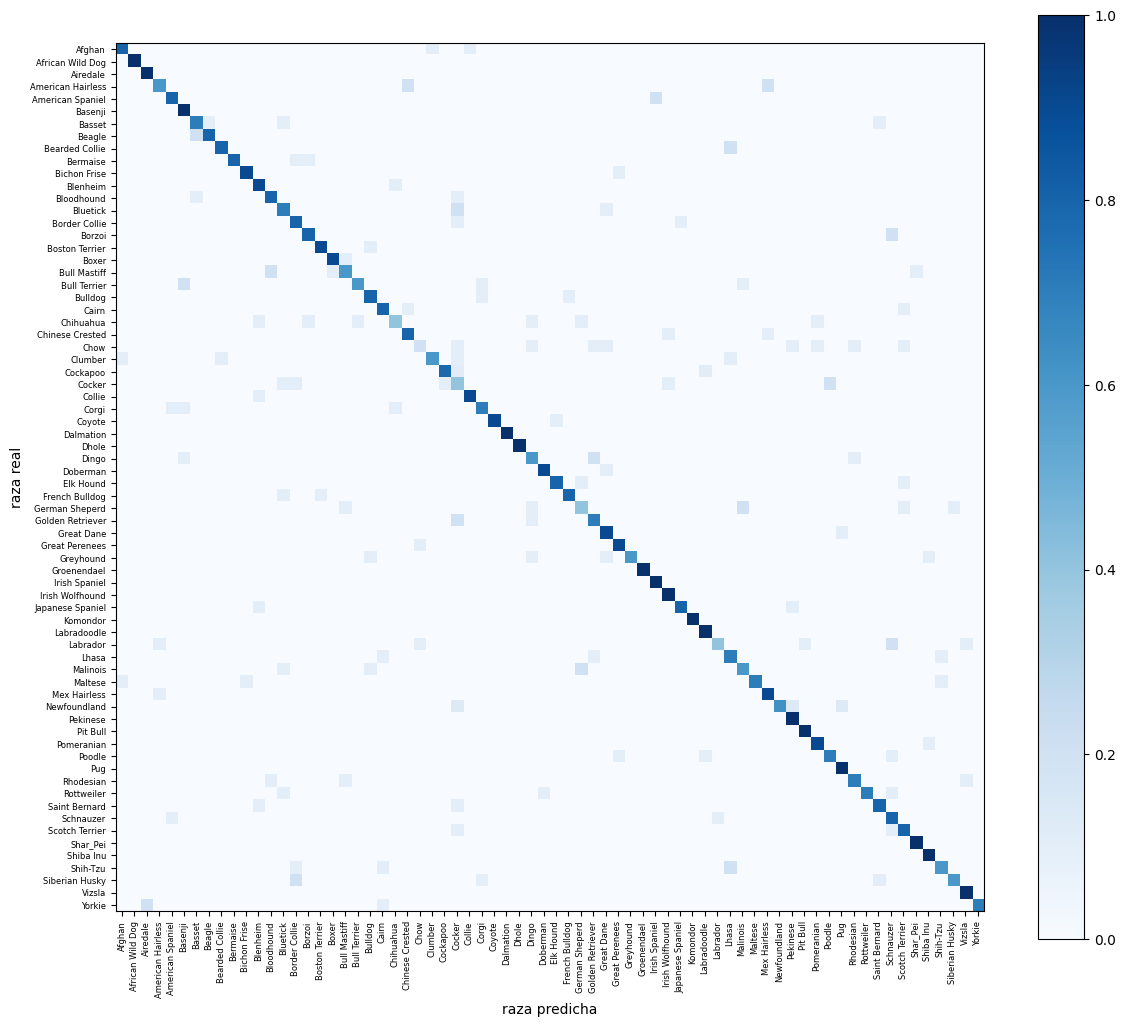

true               pred           
American Hairless  Mex Hairless       2
                   Chinese Crested    2
Malinois           German Sheperd     2
Siberian Husky     Border Collie      2
American Spaniel   Irish Spaniel      2
Bearded Collie     Lhasa              2
Beagle             Basset             2
Bluetick           Cocker             2
Bull Mastiff       Bloodhound         2
Borzoi             Schnauzer          2
Name: errores, dtype: int64

In [22]:
graficar_curvas("cnn_custom")
matriz_confusion("cnn_custom")

**Análisis (Modelo B).**
- **Curvas:** train y valid suben juntas hasta la época ~15; después se abre una brecha (93% contra 81%), señal de sobreajuste moderado. Valid es más ruidosa que en el Modelo A (caída en la época 19).
- **Matriz:** diagonal clara, pero con errores dispersos en casi todas las razas; ningún par concentra más de 2.
- **Errores distintos a los del Modelo A:** además de pares parecidos, aparecen confusiones entre razas de forma distinta (Borzoi → Schnauzer, Bluetick → Cocker, Siberian Husky → Border Collie). Hipótesis: la CNN se apoya más en el color y la textura del pelaje que en la forma.

### 7.1 Experimentos

Variantes de cada modelo, una por vez y cambiando un solo factor, para justificar la configuración elegida:
- **A2 (`layer4`)**: además de la cabeza, se descongela el último bloque de ResNet18, con lr 1e-4 (10 veces menor) para no destruir los pesos de ImageNet. Busca superar la meseta de ~94% del Modelo A.
- **B2 (dropout 0.5)**: más regularización en la cabeza de la CNN, para atacar el sobreajuste visto en sus curvas.

Cada experimento se guarda con sufijo (por ejemplo `resnet18_finetuned_layer4.pth`) sin pisar el checkpoint principal; al final se elige el mejor por accuracy de valid.

In [23]:
import copy

def experimento(modelo, etiqueta, descripcion, **cambios):
    classifier.set_active_model(modelo)
    archivos = [classifier.active_checkpoint,
                settings.output_path / f"history_{modelo}.json",
                settings.output_path / f"predictions_{modelo}_test.csv"]
    for f in archivos:  # respalda los resultados del entrenamiento principal
        shutil.copy(f, f.with_name("respaldo_" + f.name))

    config_original = copy.copy(classifier.train_config)
    for campo, valor in cambios.items():
        setattr(classifier.train_config, campo, valor)
    classifier.train_classifier()
    metricas = classifier.evaluate_classifier()
    hist = json.loads(archivos[1].read_text())
    classifier.train_config = config_original

    for f in archivos:  # el experimento queda con sufijo y se restaura el principal
        destino = f.with_name(f"{f.stem}_{etiqueta}{f.suffix}")
        f.replace(destino)
        f.with_name("respaldo_" + f.name).replace(f)
        if IN_COLAB:
            shutil.copy(destino, DRIVE_DIR)
    classifier._loaded.pop(modelo, None)  # que load_model vuelva a leer el checkpoint principal
    return {"experimento": f"{modelo} ({etiqueta})", "cambios": descripcion, "mejor val acc": hist["best_val_acc"],
            "épocas": len(hist["history"]), **metricas}

In [24]:
exp_a2 = experimento("resnet18_finetuned", "layer4", "layer4 descongelado, lr 1e-4",
                     resnet_finetune="layer4", lr=1e-4, epochs=20, patience=5)

INFO:lib.services.classifier_service:Training resnet18_finetuned: 7810 train / 693 valid images, 70 breeds
INFO:lib.services.classifier_service:Trainable params: 8429638 / 11212422 | device: cuda
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 1/20 - train loss 2.4359 acc 0.5581 | val loss 1.2456 acc 0.9105 | 29s
INFO:lib.services.classifier_service:New best val acc 0.9105 -> saved models/resnet18_finetuned.pth
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 2/20 - train loss 1.4056 acc 0.8385 | val loss 1.0551 acc 0.9509 | 27s
INFO:lib.services.classifier_service:New best val acc 0.9509 -> saved models/resnet18_finetuned.pth
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 3/20 - train loss 1.2119 acc 0.8925 | val loss 1.0204 acc 0.9481 | 29s
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 4/20 - train loss 1.1241 acc 0.9178 | val loss 0.9973 acc 0.9610 | 29s
INFO:lib.services.classifier_service:New best val acc 0.9610 -> 

In [25]:
exp_b2 = experimento("cnn_custom", "dropout05", "dropout 0.5",
                     dropout=0.5, epochs=40, patience=8)

INFO:lib.services.classifier_service:Training cnn_custom: 7810 train / 693 valid images, 70 breeds
INFO:lib.services.classifier_service:Trainable params: 1147750 / 1147750 | device: cuda
INFO:lib.services.classifier_service:[cnn_custom] epoch 1/40 - train loss 4.1345 acc 0.0461 | val loss 3.8389 acc 0.0693 | 33s
INFO:lib.services.classifier_service:New best val acc 0.0693 -> saved models/cnn_custom.pth
INFO:lib.services.classifier_service:[cnn_custom] epoch 2/40 - train loss 3.8764 acc 0.0856 | val loss 3.6468 acc 0.1198 | 31s
INFO:lib.services.classifier_service:New best val acc 0.1198 -> saved models/cnn_custom.pth
INFO:lib.services.classifier_service:[cnn_custom] epoch 3/40 - train loss 3.6731 acc 0.1268 | val loss 3.4032 acc 0.1818 | 31s
INFO:lib.services.classifier_service:New best val acc 0.1818 -> saved models/cnn_custom.pth
INFO:lib.services.classifier_service:[cnn_custom] epoch 4/40 - train loss 3.5122 acc 0.1571 | val loss 3.3416 acc 0.1760 | 30s
INFO:lib.services.classifier_

### Tabla de experimentos y elección

In [26]:
def fila_principal(experimento, descripcion, modelo, metricas):
    hist = json.loads((settings.output_path / f"history_{modelo}.json").read_text())
    return {"experimento": experimento, "cambios": descripcion, "mejor val acc": hist["best_val_acc"],
            "épocas": len(hist["history"]), **metricas}

tabla_exp = pd.DataFrame([
    fila_principal("resnet18_finetuned (head)", "backbone congelado, lr 1e-3", "resnet18_finetuned", metrics_a),
    exp_a2,
    fila_principal("cnn_custom (base)", "dropout 0.3", "cnn_custom", metrics_b),
    exp_b2,
]).set_index("experimento").round(4)
tabla_exp

,cambios,mejor val acc,épocas,accuracy,precision,recall,specificity,f1
experimento,,,,,,,,
resnet18_finetuned (head),"backbone congelado, lr 1e-3",0.9466,20,0.9526,0.9584,0.9525,0.9993,0.9517
resnet18_finetuned (layer4),"layer4 descongelado, lr 1e-4",0.9610,9,0.9583,0.9635,0.9584,0.9994,0.9579
cnn_custom (base),dropout 0.3,0.8153,40,0.7874,0.8011,0.7872,0.9969,0.7844
cnn_custom (dropout05),dropout 0.5,0.8139,40,0.7744,0.7921,0.7740,0.9967,0.7710


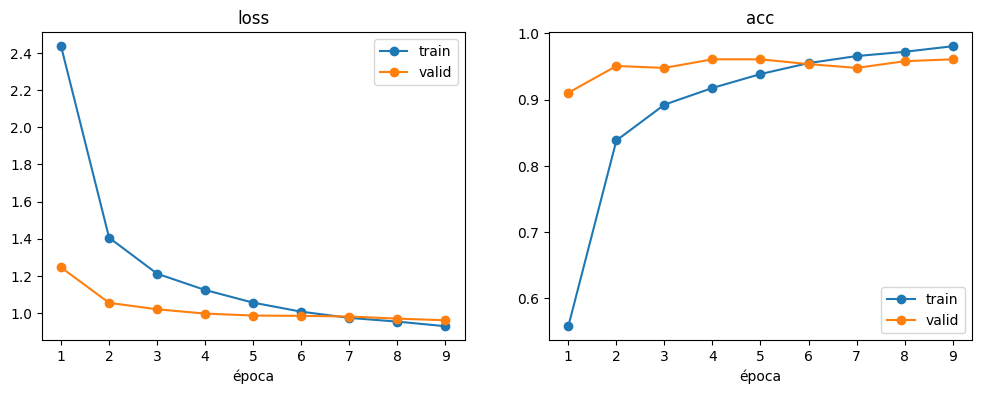

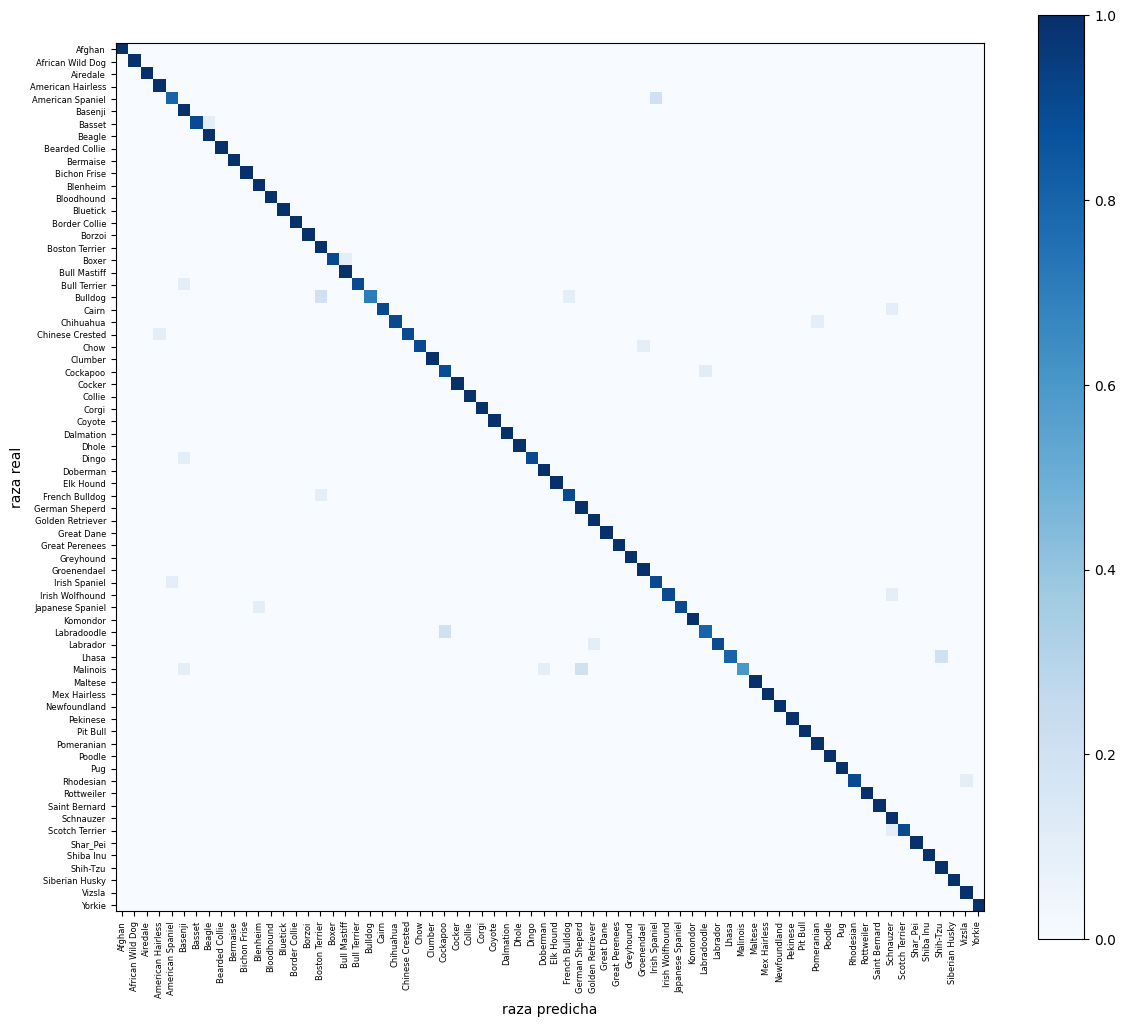

,,errores
true,pred,
American Spaniel,Irish Spaniel,2
Bulldog,Boston Terrier,2
Malinois,German Sheperd,2
Lhasa,Shih-Tzu,2
Labradoodle,Cockapoo,2
Bull Terrier,Basenji,1
Boxer,Bull Mastiff,1
Basset,Beagle,1
Chihuahua,Pomeranian,1


In [27]:
# Modelo A final = layer4 (mejor accuracy en valid). Se conserva el de head con sufijo "_head".
pares = [
    (settings.model_path / "resnet18_finetuned.pth", settings.model_path / "resnet18_finetuned_layer4.pth"),
    (settings.output_path / "history_resnet18_finetuned.json", settings.output_path / "history_resnet18_finetuned_layer4.json"),
    (settings.output_path / "predictions_resnet18_finetuned_test.csv", settings.output_path / "predictions_resnet18_finetuned_test_layer4.csv"),
]
for principal, ganador in pares:
    respaldo_head = principal.with_name(f"{principal.stem}_head{principal.suffix}")
    shutil.copy(principal, respaldo_head)
    shutil.copy(ganador, principal)
    if IN_COLAB:
        shutil.copy(respaldo_head, DRIVE_DIR)
        shutil.copy(principal, DRIVE_DIR)

classifier._loaded.pop("resnet18_finetuned", None)  # que se recargue el checkpoint nuevo
metrics_a = {k: exp_a2[k] for k in metrics_a}       # las secciones siguientes usan el modelo A final

graficar_curvas("resnet18_finetuned")
matriz_confusion("resnet18_finetuned")

**Elección.**
- **Modelo A final: `layer4`** (val 96.1% contra 94.7%; test 95.8% contra 95.3%, F1 0.958). Converge en 4 épocas y el early stopping corta en la 9; el lr 10 veces menor evitó romper los pesos de ImageNet.
- Train termina por encima de valid (98% contra 96%): con 8.4 M parámetros libres empieza a memorizar, pero se guarda el checkpoint de la época 4.
- **Mejora en los pares difíciles:** Bulldog → Boston Terrier baja de 5 errores a 2, y ningún par supera los 2.
- **Modelo B final: dropout 0.3.** El 0.5 redujo la brecha train-valid de 12 a 6 puntos, pero no mejoró valid (81.4% contra 81.5%) y bajó en test (77.4% contra 78.7%): el límite es la capacidad de una red chica entrenada desde cero, no solo el sobreajuste.

## 8. Evaluación sobre el conjunto independiente

Mismas métricas (accuracy, precision, recall, specificity, F1, macro) de los dos modelos finales sobre las 119 imágenes limpias del conjunto independiente (21 razas, fotos de Oxford-IIIT Pet y Stanford Dogs). Como el independiente tiene solo 21 razas, también se calcula la accuracy de test restringida a esas mismas razas, para comparar el cambio de dominio en igualdad de condiciones.

In [28]:
razas_ind = {raza for _, raza in independiente}

filas = {}
for modelo, metricas_test in [("resnet18_finetuned", metrics_a), ("cnn_custom", metrics_b)]:
    classifier.set_active_model(modelo)
    pred_test = pd.read_csv(settings.output_path / f"predictions_{modelo}_test.csv")
    misma = pred_test["true"].isin(razas_ind)
    filas[(modelo, "test (70 razas)")] = metricas_test
    filas[(modelo, "test (21 razas)")] = {"accuracy": (pred_test["true"] == pred_test["pred"])[misma].mean()}
    filas[(modelo, "independiente")] = classifier.evaluate_items(independiente, tag="independiente")

pd.DataFrame(filas).T.round(3)

INFO:lib.services.classifier_service:Predictions saved to output/predictions_resnet18_finetuned_independiente.csv
INFO:lib.services.classifier_service:[resnet18_finetuned] metrics on independiente: {'accuracy': 0.773109243697479, 'precision': 0.9605442176870748, 'recall': 0.7809523809523808, 'specificity': 0.9978966590517592, 'f1': 0.8322386608100893}
INFO:lib.services.classifier_service:Predictions saved to output/predictions_cnn_custom_independiente.csv
INFO:lib.services.classifier_service:[cnn_custom] metrics on independiente: {'accuracy': 0.3697478991596639, 'precision': 0.777721088435374, 'recall': 0.37142857142857144, 'specificity': 0.993682584041224, 'f1': 0.45059728631157203}


accuracy  precision  recall  specificity  \
resnet18_finetuned test (70 razas)     0.958      0.963   0.958        0.999   
                   test (21 razas)     0.971        NaN     NaN          NaN   
                   independiente       0.773      0.961   0.781        0.998   
cnn_custom         test (70 razas)     0.787      0.801   0.787        0.997   
                   test (21 razas)     0.755        NaN     NaN          NaN   
                   independiente       0.370      0.778   0.371        0.994   

                                       f1  
resnet18_finetuned test (70 razas)  0.958  
                   test (21 razas)    NaN  
                   independiente    0.832  
cnn_custom         test (70 razas)  0.784  
                   test (21 razas)    NaN  
                   independiente    0.451

**Resultados.**
- **Ambos modelos caen fuera de dominio.** Con las mismas 21 razas, el Modelo A pasa de 97.1% a 77.3% y la CNN de 75.5% a 37.0%.
- **El Modelo A queda por debajo del baseline de la Etapa 1** en el independiente (77.3% contra 84.0%): el fine-tuning lo especializó en el estilo de Kaggle (perro centrado y recortado) y perdió generalidad. En test le gana (95.8% contra 93.7%), pero test es del mismo dominio.
- **La CNN es la que peor generaliza:** entrenada desde cero, aprendió pistas propias del dataset (color, textura, encuadre).
- **Precision alta y recall bajo** (A: 0.961 contra 0.781), porque el promedio macro solo incluye las 21 razas presentes y muchos errores caen en otras razas. Acá las métricas confiables son accuracy y recall.

## 9. Embeddings de los modelos entrenados

Se repite la evaluación de la Etapa 1 (misma galería, mismas consultas, NDCG@10 con cosine) usando como embedding la penúltima capa de cada modelo entrenado (512 dimensiones en ambos), en lugar del ResNet18 de ImageNet.

Los embeddings se calculan por lotes en GPU, con el mismo preprocesamiento, `model.embed` y normalización L2 que `extract_custom_embedding` de la app; un control verifica que den lo mismo.

### 9.1 Embeddings de los Modelos A y B

In [29]:
from torch.utils.data import DataLoader
from lib.training import DogDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def embeddings_modelo(modelo, items):
    classifier.set_active_model(modelo)
    red = classifier.get_torch_model().to(device)
    loader = DataLoader(DogDataset(items, red.classes, settings.image_size), batch_size=64,
                        num_workers=2 if device.type == "cuda" else 0)
    partes = []
    with torch.no_grad():
        for imagenes, _ in loader:
            emb = torch.nn.functional.normalize(red.embed(imagenes.to(device)), dim=1)
            partes.append(emb.cpu().numpy())
    red.to("cpu")  # la app usa el modelo en CPU
    return np.concatenate(partes)

emb_modelos = {}
for modelo in ["resnet18_finetuned", "cnn_custom"]:
    emb_modelos[modelo] = {nombre: embeddings_modelo(modelo, items) for nombre, items in conjuntos.items()}
    ruta = conjuntos["test"][0][0]
    ref = np.array(classifier.extract_custom_embedding(cv2.imread(str(ruta))))
    print(f"{modelo}: igual a extract_custom_embedding -> {np.allclose(ref, emb_modelos[modelo]['test'][0], atol=1e-4)}")

resnet18_finetuned: igual a extract_custom_embedding -> True
cnn_custom: igual a extract_custom_embedding -> True


### 9.2 NDCG@10 por modelo de embeddings

In [30]:
emb_por_modelo = {"baseline": emb_base, "Modelo A": emb_modelos["resnet18_finetuned"], "Modelo B": emb_modelos["cnn_custom"]}

filas = {}
for nombre, emb in emb_por_modelo.items():
    for consulta in ["test", "independiente"]:
        r = evaluar(emb, consulta, "cosine")
        filas[(nombre, consulta)] = {"NDCG@10": r.ndcg.mean(), "precision@10": r.precision.mean(), "accuracy": r.acierto.mean()}

tabla_emb = pd.DataFrame(filas).T.round(3)
tabla_emb

NDCG@10  precision@10  accuracy
baseline test             0.874         0.861     0.937
         independiente    0.773         0.766     0.840
Modelo A test             0.942         0.939     0.961
         independiente    0.767         0.761     0.798
Modelo B test             0.684         0.664     0.772
         independiente    0.317         0.308     0.403

### 9.3 Visualización t-SNE (test)

Embeddings de `test` de 10 razas proyectados a 2D con t-SNE, para los tres modelos lado a lado. Se eligen pares que se confunden (Bulldog / Boston Terrier / French Bulldog, German Sheperd / Malinois, Labradoodle / Cockapoo) y razas distintivas como referencia.

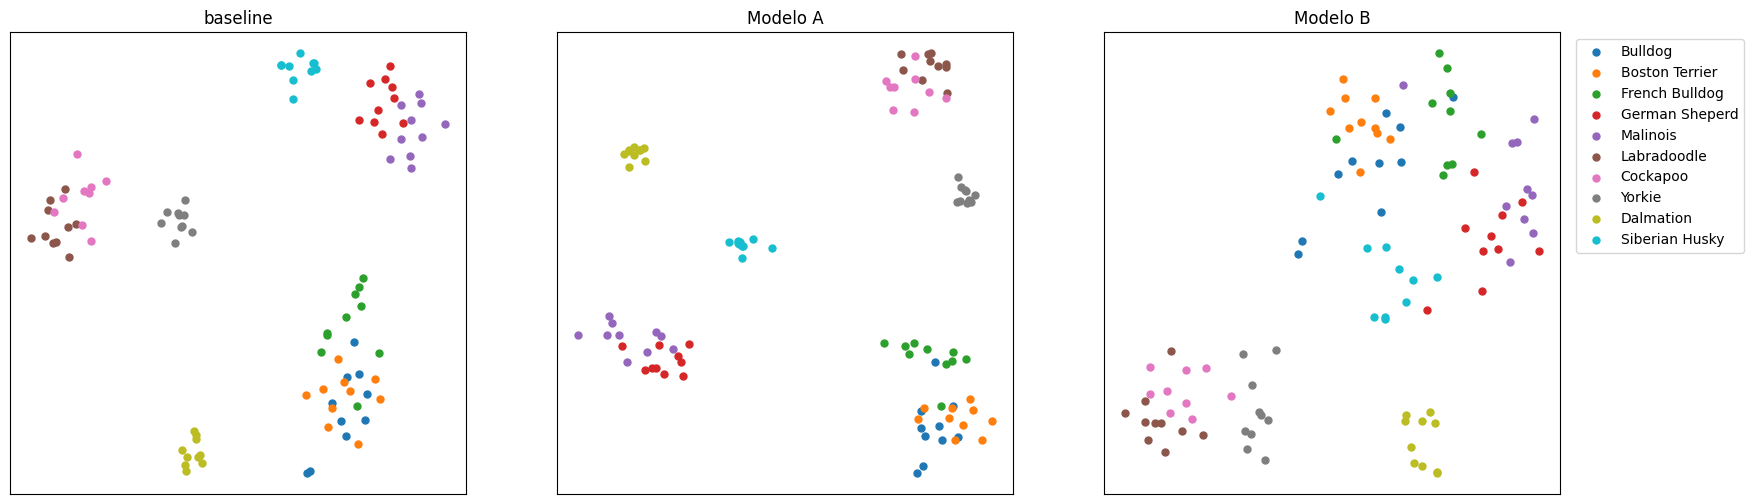

In [31]:
from sklearn.manifold import TSNE

razas_tsne = ["Bulldog", "Boston Terrier", "French Bulldog", "German Sheperd", "Malinois",
              "Labradoodle", "Cockapoo", "Yorkie", "Dalmation", "Siberian Husky"]
razas_test = np.array([raza for _, raza in splits["test"]])
mask = np.isin(razas_test, razas_tsne)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (nombre, emb) in zip(axes, emb_por_modelo.items()):
    puntos = TSNE(n_components=2, random_state=42).fit_transform(emb["test"][mask])
    for raza in razas_tsne:
        sel = razas_test[mask] == raza
        ax.scatter(puntos[sel, 0], puntos[sel, 1], label=raza, s=25)
    ax.set_title(nombre); ax.set_xticks([]); ax.set_yticks([])
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Resultados.**
- **Modelo A: los mejores embeddings dentro del dominio** (NDCG@10 en test 0.942 contra 0.874 del baseline). En el t-SNE, los grupos son más compactos y separados, y French Bulldog se separa del par Bulldog / Boston Terrier.
- **Fuera de dominio no mejora:** en el independiente empata en NDCG (0.767 contra 0.773) y acierta menos la raza (0.798 contra 0.840).
- **Lo que ningún modelo separa:** Bulldog y Boston Terrier siguen mezclados (coherente con las etiquetas dudosas); German Sheperd / Malinois y Labradoodle / Cockapoo quedan pegados.
- **Modelo B: embeddings pobres** (NDCG 0.684 en test y 0.317 en el independiente), con grupos difusos salvo razas de pelaje muy característico, como Dalmation.

## 10. Análisis de errores

En clasificación multiclase, cada error es a la vez un **falso negativo** de la raza real (no se la reconoció) y un **falso positivo** de la raza predicha (se la asignó de más). Se analiza:
- las razas con peor recall de cada modelo, en test y en el independiente;
- si el modelo "sabe" cuándo se equivoca (score de los aciertos contra el de los errores);
- los errores con mayor confianza del Modelo A, con la imagen y su score.

In [32]:
def predicciones(modelo, tag):
    return pd.read_csv(settings.output_path / f"predictions_{modelo}_{tag}.csv")

def recall_por_raza(modelo, tag):
    pred = predicciones(modelo, tag)
    return (pred["true"] == pred["pred"]).groupby(pred["true"]).mean()

recall = pd.DataFrame({f"{nombre} {tag}": recall_por_raza(modelo, tag)
                       for nombre, modelo in [("A", "resnet18_finetuned"), ("B", "cnn_custom")]
                       for tag in ["test", "independiente"]})
print("Peor recall del Modelo A en test:")
display(recall.sort_values("A test").head(8).round(2))
print("Peor recall del Modelo A en el independiente:")
display(recall.dropna().sort_values("A independiente").head(8).round(2))

print("Score mediano (probabilidad softmax de la raza predicha):")
for modelo in ["resnet18_finetuned", "cnn_custom"]:
    for tag in ["test", "independiente"]:
        pred = predicciones(modelo, tag)
        acierto = pred["true"] == pred["pred"]
        print(f"  {modelo} {tag}: aciertos {pred.score[acierto].median():.2f} | errores {pred.score[~acierto].median():.2f}")

Peor recall del Modelo A en test:


,A test,A independiente,B test,B independiente
true,,,,
Malinois,0.60,NaN,0.60,NaN
Bulldog,0.70,NaN,0.80,NaN
Labradoodle,0.80,NaN,1.00,NaN
American Spaniel,0.80,NaN,0.80,NaN
Lhasa,0.80,NaN,0.70,NaN
Cockapoo,0.89,NaN,0.78,NaN
Boxer,0.90,0.17,0.90,0.00
Basset,0.90,0.83,0.70,0.17


Peor recall del Modelo A en el independiente:


,A test,A independiente,B test,B independiente
true,,,,
Boxer,0.9,0.17,0.9,0.00
Beagle,1.0,0.33,0.8,0.17
Pit Bull,1.0,0.33,1.0,0.17
Shiba Inu,1.0,0.50,1.0,0.17
Labrador,0.9,0.67,0.4,0.17
Chihuahua,0.9,0.67,0.4,0.17
German Sheperd,1.0,0.80,0.4,0.40
Rottweiler,1.0,0.80,0.7,0.20


Score mediano (probabilidad softmax de la raza predicha):
  resnet18_finetuned test: aciertos 0.90 | errores 0.59
  resnet18_finetuned independiente: aciertos 0.78 | errores 0.41
  cnn_custom test: aciertos 0.76 | errores 0.39
  cnn_custom independiente: aciertos 0.54 | errores 0.31


### Errores con mayor confianza (Modelo A)

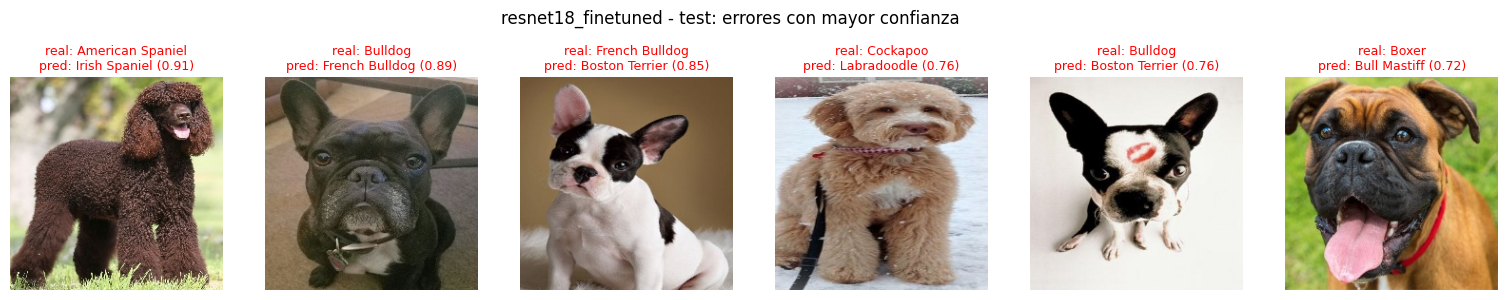

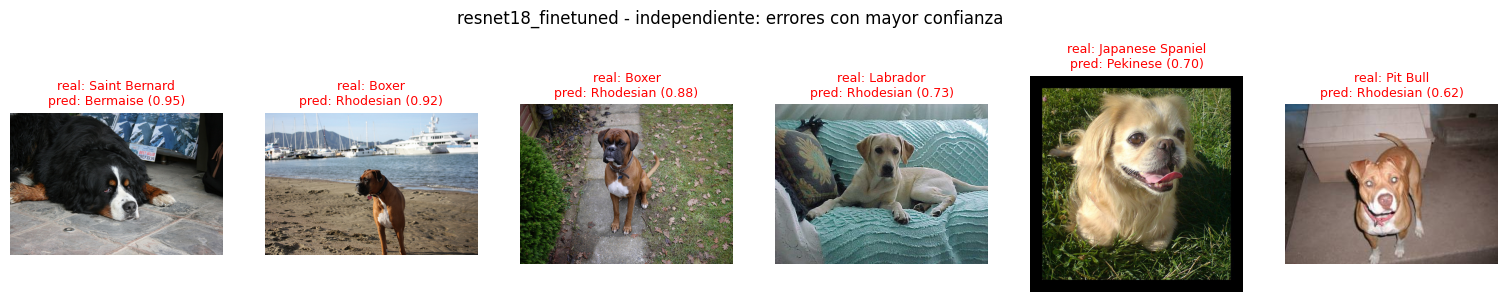

In [33]:
def mostrar_errores(modelo, tag, n=6):
    pred = predicciones(modelo, tag)
    errores = pred[pred["true"] != pred["pred"]].sort_values("score", ascending=False).head(n)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.6))
    for ax, fila in zip(axes, errores.itertuples()):
        ax.imshow(cv2.cvtColor(cv2.imread(fila.path), cv2.COLOR_BGR2RGB))
        ax.set_title(f"real: {fila.true}\npred: {fila.pred} ({fila.score:.2f})", fontsize=9, color="red")
    for ax in axes:
        ax.axis("off")
    plt.suptitle(f"{modelo} - {tag}: errores con mayor confianza")
    plt.show()

mostrar_errores("resnet18_finetuned", "test")
mostrar_errores("resnet18_finetuned", "independiente")

**Análisis de errores.**
- **Peores razas:** en test, los pares parecidos de siempre (Malinois 6 de 10, Bulldog 7 de 10). En el independiente caen razas perfectas en test: Boxer 1 de 6, Beagle y Pit Bull 2 de 6.
- **El modelo sabe cuándo duda:** el score mediano de los errores es 0.59, contra 0.90 de los aciertos (test). Un umbral de confianza permitiría responder `unknown` (mejora opcional no implementada).
- **En test, varios errores parecen etiquetas mal puestas.** Los dos "Bulldog" predichos como French Bulldog y Boston Terrier tienen orejas de murciélago y pelaje blanco y negro: el modelo probablemente acierta. Lo mismo pasa con el American Spaniel de pelo rizado (→ Irish Spaniel). El resto son razas casi idénticas (Cockapoo / Labradoodle, Boxer / Bull Mastiff).
- **En el independiente, el problema es el encuadre.** Boxer, Labrador y Pit Bull de cuerpo entero y lejos de la cámara se predicen como Rhodesian. En Kaggle los Boxer aparecen en primer plano de la cara, y con el perro chico el modelo decide por color y silueta. El "Saint Bernard" → Bermaise parece un Boyero de Berna (posible etiqueta errónea de origen).

## 11. Costo computacional

Para cada modelo: parámetros, tamaño en memoria (float32: 4 bytes por parámetro), tiempo de inferencia por imagen en **CPU** (batch 1, promedio de 50 pasadas tras 5 de calentamiento; la app corre en CPU) y dimensión del embedding.

In [34]:
import time

def costo(nombre, red):
    red = red.to("cpu").eval()
    x = torch.randn(1, 3, settings.image_size, settings.image_size)
    with torch.no_grad():
        dim = (red.embed(x) if hasattr(red, "embed") else red(x)).shape[1]
        for _ in range(5):  # calentamiento
            red(x)
        inicio = time.perf_counter()
        for _ in range(50):
            red(x)
    params = sum(p.numel() for p in red.parameters())
    return {"modelo": nombre, "parámetros (M)": params / 1e6, "tamaño (MB)": params * 4 / 1e6,
            "ms por imagen (CPU)": (time.perf_counter() - inicio) / 50 * 1000, "dim. embedding": dim}

filas = [costo("baseline (ResNet18 ImageNet)", similarity._get_baseline_model())]
for nombre, modelo in [("Modelo A (ResNet18 layer4)", "resnet18_finetuned"), ("Modelo B (CNN propia)", "cnn_custom")]:
    classifier.set_active_model(modelo)
    filas.append(costo(nombre, classifier.get_torch_model()))

tabla_costo = pd.DataFrame(filas).set_index("modelo").round(2)
tabla_costo

,parámetros (M),tamaño (MB),ms por imagen (CPU),dim. embedding
modelo,,,,
baseline (ResNet18 ImageNet),11.18,44.71,113.55,512
Modelo A (ResNet18 layer4),11.21,44.85,101.06,512
Modelo B (CNN propia),1.15,4.59,41.46,512


**Resultados.**
- **Baseline y Modelo A cuestan lo mismo:** la misma arquitectura ResNet18 (11.2 M parámetros, ~45 MB). La cabeza propia agrega solo 36 mil parámetros, y la diferencia de tiempo entre ambos (114 contra 101 ms) es variación de la medición.
- **La CNN propia es 10 veces más chica** (1.15 M parámetros, 4.6 MB) y **unas 2.5 veces más rápida** (41 ms por imagen).
- Los tres generan embeddings de **512 dimensiones**: cambiar de modelo de búsqueda no requiere cambiar `EMBEDDING_DIM` ni la tabla de pgvector, solo reindexar.
- Los tiempos son de la CPU de Colab (2 núcleos); en una PC común son unas 4 veces menores (medido en local: ~24 ms para ResNet18 y ~15 ms para la CNN). En todos los casos alcanza para uso interactivo en la app.
- **Trade-off:** la CNN gana en tamaño y velocidad, pero pierde 17 puntos de accuracy en test y 40 en el independiente. Para esta app, que procesa una imagen por consulta, ~100 ms no son un problema: conviene priorizar precisión.

## 12. Etapa 3 — Validación del detector YOLO

Se prueba la misma `detect_dogs` de la app (YOLOv8n preentrenado en COCO, clase `dog`) con 3 valores de `YOLO_CONF_THRESHOLD` sobre el conjunto independiente:
- **limpias** (119, un perro cada una),
- **escenas** de Stanford con 2 a 4 perros (12, cantidad según sus anotaciones), algunas con personas,
- **sin perro** (10 gatos).

Se cuentan los perros detectados contra los reales y las imágenes con el conteo exacto.

In [35]:
from lib.bootstrap import build_detection

detection = build_detection(settings, classifier)
detection.yolo_model_name = str(settings.model_path / "yolov8n.pt")  # ultralytics lo descarga ahí si no existe

fuentes["perros"] = fuentes.fuente.str.extract(r"\((\d+) perros")[0].astype(float).fillna(fuentes.tipo.map({"limpia": 1, "sin_perro": 0}))
imagenes = {fila.archivo: cv2.imread(str(ind_dir / fila.archivo)) for fila in fuentes.itertuples()}

filas = []
for conf in [0.10, 0.25, 0.50]:
    detection.conf_threshold = conf
    detectados = fuentes.archivo.map(lambda a: len(detection.detect_dogs(imagenes[a])))
    for tipo in ["limpia", "escena", "sin_perro"]:
        m = fuentes.tipo == tipo
        filas.append({"conf": conf, "tipo": tipo, "imágenes": m.sum(), "perros reales": int(fuentes.perros[m].sum()),
                      "perros detectados": int(detectados[m].sum()),
                      "imgs con conteo exacto": int((detectados[m] == fuentes.perros[m]).sum())})
pd.DataFrame(filas)

INFO:lib.services.detection_service:Loading YOLO detector: models/yolov8n.pt


,conf,tipo,imágenes,perros reales,perros detectados,imgs con conteo exacto
0,0.10,limpia,119,119,121,103
1,0.10,escena,12,28,26,8
2,0.10,sin_perro,10,0,1,9
3,0.25,limpia,119,119,113,103
4,0.25,escena,12,28,23,7
5,0.25,sin_perro,10,0,1,9
6,0.50,limpia,119,119,105,99
7,0.50,escena,12,28,16,4
8,0.50,sin_perro,10,0,1,9


### Ejemplos con el umbral actual del `.env` (0.25)

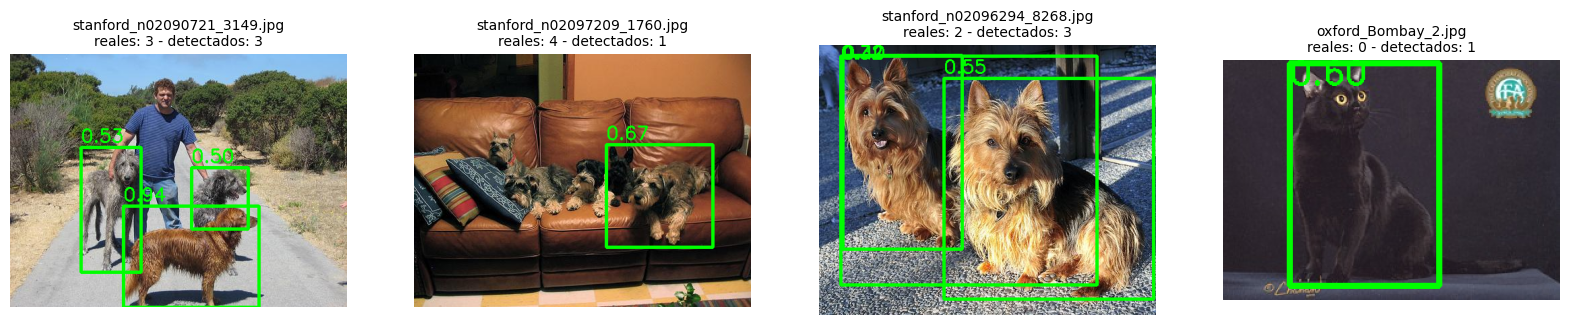

In [36]:
detection.conf_threshold = 0.25
mostrar = ["_escenas/stanford_n02090721_3149.jpg", "_escenas/stanford_n02097209_1760.jpg",
           "_escenas/stanford_n02096294_8268.jpg", "_sin_perro/oxford_Bombay_2.jpg"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, archivo in zip(axes, mostrar):
    img = imagenes[archivo].copy()
    dets = detection.detect_dogs(img)
    for (x1, y1, x2, y2), c in dets:
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(img, f"{c:.2f}", (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 0), 2)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{archivo.split('/')[-1]}\nreales: {int(fuentes.set_index('archivo').perros[archivo])} - detectados: {len(dets)}", fontsize=10)
    ax.axis("off")
plt.show()

**Resultados y elección del umbral.**
- **0.10:** detecta más perros en las escenas (26 de 28), pero agrega detecciones de más en las imágenes de un solo perro (121 cajas para 119 perros: recuadros duplicados).
- **0.50:** pierde muchos perros reales: 16 de 28 en escenas y 105 de 119 en las limpias. Los perros parcialmente tapados o lejanos suelen tener confianza entre 0.2 y 0.5.
- **0.25:** el mejor equilibrio. Detecta 23 de 28 perros en escenas y 113 de 119 en las limpias, con conteo exacto en 103 de ellas (igual que 0.10, sin las cajas de más). **Se mantiene `YOLO_CONF_THRESHOLD=0.25`.**
- **Gatos:** 9 de 10 sin detecciones con cualquier umbral. El que falla es un gato negro (Bombay) detectado como perro con 0.60: es un error del propio YOLO, no del umbral, y ningún valor razonable lo evita.
- **Limitaciones vistas en los ejemplos:** en la escena con una persona detecta los 3 perros. En el sillón detecta 1 de 4: los perros están pegados y superpuestos, y YOLO los junta o los descarta. En los dos terriers agrega una caja grande que abarca a los dos (0.32), un duplicado que pasa el umbral.

## 13. Comparación y elección final

Tablas resumen con los resultados de las secciones anteriores (mismos conjuntos y mismas métricas para todos los modelos).

In [37]:
def acc_independiente(modelo):
    pred = predicciones(modelo, "independiente")
    return (pred["true"] == pred["pred"]).mean()

print("Etapa 1 — Búsqueda por similitud (galería = train, cosine, TOP_K=10)")
etapa1 = pd.DataFrame({
    nombre: {"dim": 512,
             "NDCG@10 test": tabla_emb.loc[(nombre, "test"), "NDCG@10"],
             "NDCG@10 independiente": tabla_emb.loc[(nombre, "independiente"), "NDCG@10"],
             "accuracy test": tabla_emb.loc[(nombre, "test"), "accuracy"],
             "accuracy independiente": tabla_emb.loc[(nombre, "independiente"), "accuracy"]}
    for nombre in ["baseline", "Modelo A", "Modelo B"]
}).T
display(etapa1.round(3))

print("Etapa 2 — Clasificación supervisada")
etapa2 = pd.DataFrame({
    nombre: {**metricas, "accuracy independiente": acc_independiente(modelo),
             "parámetros (M)": tabla_costo.loc[fila_costo, "parámetros (M)"],
             "tamaño (MB)": tabla_costo.loc[fila_costo, "tamaño (MB)"],
             "ms por imagen (CPU)": tabla_costo.loc[fila_costo, "ms por imagen (CPU)"]}
    for nombre, modelo, metricas, fila_costo in [
        ("Modelo A (ResNet18 layer4)", "resnet18_finetuned", metrics_a, "Modelo A (ResNet18 layer4)"),
        ("Modelo B (CNN propia)", "cnn_custom", metrics_b, "Modelo B (CNN propia)"),
    ]
})
display(etapa2.round(3))

Etapa 1 — Búsqueda por similitud (galería = train, cosine, TOP_K=10)


,dim,NDCG@10 test,NDCG@10 independiente,accuracy test,accuracy independiente
baseline,512.0,0.874,0.773,0.937,0.840
Modelo A,512.0,0.942,0.767,0.961,0.798
Modelo B,512.0,0.684,0.317,0.772,0.403


Etapa 2 — Clasificación supervisada


,Modelo A (ResNet18 layer4),Modelo B (CNN propia)
accuracy,0.958,0.787
precision,0.963,0.801
recall,0.958,0.787
specificity,0.999,0.997
f1,0.958,0.784
accuracy independiente,0.773,0.370
parámetros (M),11.210,1.150
tamaño (MB),44.850,4.590
ms por imagen (CPU),101.060,41.460


**Elección para la app.**
- **Clasificación (Etapas 2 y 3): Modelo A (`layer4`).** Es el mejor en todo: test 95.8% contra 78.7% e independiente 77.3% contra 37.0%. Pesa más (45 MB contra 4.6 MB), pero ~100 ms por imagen en CPU alcanza para la app.
- **Búsqueda (Etapa 1): embeddings baseline, umbral 0.82 (cosine).** El Modelo A gana en test (NDCG 0.942 contra 0.874), pero empata en el independiente (0.767 contra 0.773) y acierta menos la raza (0.798 contra 0.840). Como la búsqueda se usa con fotos propias, se prioriza la robustez. Además, el umbral ya está calibrado y la base indexada con estos embeddings.
- **Similitud vs. clasificación:** la búsqueda no requiere entrenar, admite razas nuevas con solo indexar, muestra ejemplos y puede responder `unknown`. La clasificación es más precisa dentro del dominio y no necesita galería, pero solo conoce las 70 razas y siempre elige alguna.
- **Trade-off:** la CNN es 10 veces más chica y 2.5 veces más rápida, pero pierde 17 puntos en test y 40 fuera de dominio: el transfer learning compensa su costo.

## 14. Checkpoints

Los checkpoints finales son models/resnet18_finetuned.pth (Modelo A, estrategia layer4) y models/cnn_custom.pth (Modelo B, dropout 0.3). También quedan en Google Drive junto con las variantes de los experimentos (sufijos _head, _layer4, _dropout05). Para usar la app hay que colocarlos en models/ del proyecto.

*Descarga (link público de solo lectura):* [carpeta TP2_perros en Google Drive](https://drive.google.com/drive/folders/1WnbeiZCLiiL_dbsBIPEEw1tqZpgT149K?usp=sharing)

In [38]:
!ls -lh models/

try:
    from google.colab import files

    files.download(str(settings.model_path / settings.resnet18_model_name))
    files.download(str(settings.model_path / settings.cnn_custom_model_name))
except ImportError:
    print("Fuera de Colab: los checkpoints quedan en models/")

total 144M
-rw-r--r-- 1 root root 4.5M Nov 26 01:38 cnn_custom_dropout05.pth
-rw-r--r-- 1 root root 4.5M Nov 26 01:19 cnn_custom.pth
-rw-r--r-- 1 root root  43M Nov 26 01:42 resnet18_finetuned_head.pth
-rw-r--r-- 1 root root  43M Nov 26 01:15 resnet18_finetuned_layer4.pth
-rw-r--r-- 1 root root  43M Nov 26 01:42 resnet18_finetuned.pth
-rw-r--r-- 1 root root 6.3M Nov 26 02:03 yolov8n.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
# Respaldo de todo lo generado (para trabajar después en local sin reentrenar)
if IN_COLAB:
    for modelo, emb in emb_modelos.items():
        np.savez(settings.output_path / f"emb_{modelo}.npz", **emb)
    shutil.make_archive("/content/output_tp2", "zip", settings.output_path)
    shutil.copy("/content/output_tp2.zip", DRIVE_DIR)
    print("Respaldo en Drive:", sorted(p.name for p in DRIVE_DIR.iterdir()))

Respaldo en Drive: ['cnn_custom.pth', 'cnn_custom_dropout05.pth', 'emb_baseline.npz', 'history_cnn_custom.json', 'history_cnn_custom_dropout05.json', 'history_resnet18_finetuned.json', 'history_resnet18_finetuned_head.json', 'history_resnet18_finetuned_layer4.json', 'output_tp2.zip', 'predictions_cnn_custom_test_dropout05.csv', 'predictions_resnet18_finetuned_test.csv', 'predictions_resnet18_finetuned_test_head.csv', 'predictions_resnet18_finetuned_test_layer4.csv', 'resnet18_finetuned.pth', 'resnet18_finetuned_head.pth', 'resnet18_finetuned_layer4.pth', 'splits.csv']
